## The Ising Model

- A mathematical model used in statistical mechanics to study phase transitions.
- Proposed by Wilhelm Lenz and further developed by Ernst Ising in 1925.
- Describes a system of discrete spin variables arranged on a lattice.
- Spins interact with nearest neighbors, leading to emergent patterns.
- Imagine a lattice of tiny atomic magnets—spins—that interact with their neighbors.
- Or think about a binary decision-making process: each spin is like a person choosing between two options, influenced by their neighbors.


## Energy

- Consider a two-dimensional square lattice where each site contains a spin variable.
- Each spin can take values $S_i = \pm 1$.
- Spins interact with their nearest neighbors according to an interaction strength $J$.
- The total energy of the system is given by the Hamiltonian:

  $$
  H = -J \sum_{\langle i,j \rangle} S_i S_j - h \sum_i S_i
  $$

- The first term represents spin–spin interactions, while the second term accounts for an external magnetic field $h$.

## References:

- Taroni, A. (2015). 90 years of the Ising model. Nature Physics, 11(12), 997–997. https://doi.org/10.1038/nphys3595 (for the story)
- Chandler, D. (1987). Introduction to Modern Statistical Mechanics. Oxford University Press (Excellent book.)


## Statistical Mechanics

- The probability of a given spin configuration $S$ follows the Boltzmann distribution:

  $$
  P(S) = \frac{e^{-H(S) / k_{\rm B} T}}{Z}
  $$

- The partition function $Z$ normalizes the probability distribution:

  $$
  Z = \sum_{\{S\}} e^{-H(S) / k_{\rm B} T}
  $$

- Important observables derived from this formulation include the magnetization:

  $$
  M = \frac{1}{N} \sum_i S_i
  $$

- And the susceptibility:

  $$
  \chi = \frac{1}{k_{\rm B} T} (\langle M^2 \rangle - \langle M \rangle^2)
  $$


## Phase Transition in 2D Ising Model

- The 2D Ising model undergoes a phase transition at a critical temperature $T_c$.
- Below $T_c$, the system exhibits spontaneous magnetization.
- Above $T_c$, the system is in a disordered phase.
- The exact critical temperature for a square lattice with zero external field is:

  $$
  T_{\rm C} = \frac{2 J}{k_{\rm B} \ln(1+\sqrt{2})}
  $$

- This transition is an example of spontaneous symmetry breaking.



## Monte Carlo (MC) Methods

MC methods are useful for solving problems that are analytically intractable or computationally complex. Instead of averaging over all states, MC methods sample a subset of phase space to approximate "ensemble averages" with the following steps:

1. Randomly select a new configuration (using a Markov Chain)
2. Accept/reject the configuration based on a chosen strategy.  
3. Compute the physical quantity and update the average.  
4. Repeat the process.  

Figure from: Böttcher, L., & Herrmann, H. J. (2021). Computational Statistical Physics (1st ed.). Cambridge University Press. https://doi.org/10.1017/9781108882316 p. 68

![](images/MC.png)

### Example: Computation of Integrals

- Monte Carlo integration is especially efficient for high-dimensional problems.
- Given a function $g(x)$ over an interval $[a, b]$, simple sampling approximates the integral as:
$$
\int_a^b g(x){\rm d}x \approx (b - a) \frac{1}{N} \sum_{i=1}^{N} g(x_i)
$$  
where $x_i$ are randomly chosen points. 
- If $g(x)$ is not smooth, importance sampling can improve accuracy by choosing sample points based on a probability density function $p(x)$ for which $g(x)/p(x)$ is smooth. This gives:  
$$
\int_a^b g(x){\rm d}x = \int_a^b \frac{g(x)}{p(x)} p(x){\rm d}x \approx (b - a) \frac{1}{N} \sum_{i=1}^{N} \frac{g(x_i)}{p(x_i)}
$$  
- In essence, $p(x)$ helps to *choose* sampling points according to their importance (e. g., choosing more points close to a singularity). This is know as **importance sampling**.

### Comparison of errors in MC and other methods

- In conventional methods (e.g., trapezoidal rule), the error scales as $\mathcal{O}(N^{-2/d})$.
- The error in MC estimate for $Q = \int_{a_1}^{b_1} {\rm d}x_1 \int_{a_2}^{b_2} {\rm d}x_2 \dots \int_{a_n}^{b_n} {\rm d}x_n\; g(x_1, \dots, x_n)$
decreases with increasing number of sampling points ($N$) as $\mathcal{O}(N^{-1/2})$, independent of dimension.
- MC becomes more efficient than the trapezoidal rule when $d > 4$. (see Böttcher and Hermann, pp. 66–71 if you're interested in derivations)
- Thus, MC methods are preferred for high-dimensional integrals, while conventional methods work well for low-dimensional cases.

## References



- **(For a quick reminder of probability theory)** Grinstead, C. M., & Snell, J. L. (2006). Introduction to Probability. American Mathematical Society. https://math.dartmouth.edu/~prob/prob/prob.pdf
- **(If you want to know *much more* about MC methods from CS perspective.)**: Check CMU's [Keenan Crane's course webpage](https://gi1242.codeberg.page/cmu-math-cs-mcm/)


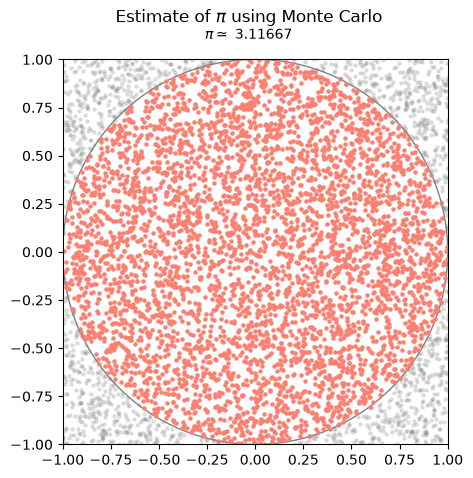

In [2]:
# Compute pi with Monte Carlo (uniform sampling as importance sampling is not required.)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

n, step = 5000, 500
frames = n // step
x_in, y_in, x_out, y_out = [], [], [], []

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-1, 1), ax.set_ylim(-1, 1), ax.set_aspect('equal')
# fig.subplots_adjust(top=0.85)
fig.suptitle(r"Estimate of $\pi$ using Monte Carlo")
pi_txt = fig.text(0.5, 0.92, "", ha="center")

ax.add_patch(plt.Circle((0, 0), 1, color='gray', fill=False))
sc_in = ax.scatter([], [], color="salmon", s=5, alpha=1)
sc_out = ax.scatter([], [], color="gray", s=5, alpha=0.2)

def update(_):
    x, y = np.random.uniform(-1, 1, step), np.random.uniform(-1, 1, step)
    inside = x**2 + y**2 <= 1
    x_in.extend(x[inside]), y_in.extend(y[inside])
    x_out.extend(x[~inside]), y_out.extend(y[~inside])
    pi_txt.set_text(rf"$\pi \simeq$ {4 * len(x_in) / (len(x_in) + len(x_out)):.5f}")
    sc_in.set_offsets(np.c_[x_in, y_in])
    sc_out.set_offsets(np.c_[x_out, y_out])
    return sc_in, sc_out, pi_txt

ani = animation.FuncAnimation(fig, update, frames=frames, interval=1, blit=False);
ani.save("monte_carlo_pi.gif", writer="pillow", fps=5);



## Markov Chains

In many physical cases, uniform random sampling of the phase space is inefficient. The underlying distribution may have sharp peaks and regions where it is nearly zero. For instance, the kinetic energy distribution of an ideal gas exhibits a sharp peak that becomes more pronounced as the system size increases.

### Importance Sampling & Markov Chains

Importance sampling are often efficient. For example, let a Markov chain evolves a configuration $X$ to another one $Y$ with probability $T(X \to Y)$, with the following properties:

1. **Ergodicity**: Any state $X$ is reachable after a finite number of steps: $T(X \to Y) > 0$
2. **Normalization**: The sum of transition probabilities must be unity: $\sum_Y T(X \to Y) = 1$
3. **Reversibility**: Transition probabilities satisfy: $T(X \to Y) = T(Y \to X)$

#### Acceptance Probability & Markov Chain Probability

Not all proposed transitions are accepted. For example, in the Ising model, a proposed transition increasing the system’s energy may be rejected, especially at low temperatures. To handle this, we introduce an **acceptance probability** $A(X \to Y)$, defining the probability that $Y$ is accepted after transitioning from $X$.

The total probability of a transition in the Markov chain is: $W(X \to Y) = T(X \to Y) \cdot A(X \to Y).$

#### Master Equation

The probability $p(X, \tau)$ of finding the system in configuration $X$ at time $\tau$ follows the **master equation**: 

$$\frac{dp(X, \tau)}{d\tau} = \sum_{Y \neq X} p(Y) W(Y \to X) - \sum_{Y \neq X} p(X) W(X \to Y).$$

This describes how probability flows between configurations.

Like $T(X \to Y)$, $W(X \to Y)$ has key properties:
1. **Ergodicity**: Every state must be reachable: $\forall X, Y \quad W(X \to Y) > 0$
2. **Normalization**: The sum over all transitions must be unity: $\sum_Y W(X \to Y) = 1$
3. **Homogeneity**: Summing over all initial states yields: $\sum_Y p(Y) W(Y \to X) = p(X).$

#### Stationary Distribution & Detailed Balance

- A Markov chain satisfying these properties converges to a unique stationary distribution $p_{\rm st}$ that *does not change over time*: $\frac{{\rm d} p_{\rm st}(X, \tau)}{{\rm d}\tau} = 0.$

- For thermodynamic sampling, this stationary distribution is set to the **equilibrium distribution** $p_{\rm eq}$: $p_{\rm st} \equiv p_{\rm eq}.$

- From the stationary condition: $\sum_{Y \neq X} p_{\rm eq}(Y) W(Y \to X) = \sum_{Y \neq X} p_{\rm eq}(X) W(X \to Y),$

which can be simplified to the **condition of detailed balance** (of course, other solutions are possible)

$$p_{\rm eq}(X) W(X \to Y) = p_{\rm eq}(Y) W(Y \to X).$$

In the **canonical ensemble** at temperature $T$, the equilibrium distribution is given by the **Boltzmann distribution**: $p_{\rm eq}(X) = \frac{1}{Z} \exp \left[ -\frac{E(X)}{k_{\rm B} T} \right],$

where $Z$ is the normalization factor (also called a *partition function*): $Z = \sum_X \exp \left[ -\frac{E(X)}{k_{\rm B} T} \right].$


### Metropolis Algorithm

- The Metropolis algorithm is a Monte Carlo method that satisfies the detailed balance condition by using an acceptance probability: 
$$
A(X \to Y) = \min \left[1, \frac{p_{\rm eq}(Y)}{p_{\rm eq}(X)} \right]
$$
- Please read about [Arianna Rosenbluth](https://en.wikipedia.org/wiki/Arianna_W._Rosenbluth) and how she didn't received the credits she deserved for creating the algorithm. Science—as practiced—is sometimes imperfect; this is a stark example. 
- For a canonical ensemble, where $p_{\rm eq}(X) \propto e^{-E(X) / k_{\rm B} T}$, this results in:

$$
A(X \to Y) = \min \left[ 1, \exp \left( -\frac{\Delta E}{k_B T} \right) \right]
$$

- If $\Delta E < 0$, the move is always accepted.  
- If $\Delta E > 0$, the move is accepted with probability $e^{-\Delta E / k_{\rm B} T}$.  

## Monte Carlo Simulation: Metropolis Algorithm

- The Ising model is typically simulated using Monte Carlo methods.
- The Metropolis algorithm is an efficient Markov Chain Monte Carlo (MCMC) method.

## Algorithm Steps:
1. Select a random spin $S_i$.
2. Compute the energy change if the spin is flipped:

   $$
   \Delta E = 2 J S_i \sum_{\text{nn}} S_j
   $$

3. Accept the flip with probability

   $$
   P = \min(1, e^{-\Delta E / k_{\rm B} T})
   $$

4. Iterate till equilibrium.

## References:

- *Really good book, if you ever want to use computational physics*: Böttcher, L., & Herrmann, H. J. (2021). Computational Statistical Physics (1st ed.). Cambridge University Press. https://doi.org/10.1017/9781108882316


In [5]:
# `np.random.rand()` returns a uniform random number in [0, 1), so comparing it to a probability `p` is `True` with probability `p`. This is how the Metropolis rule accepts an energy-raising flip with probability `exp(-beta * dE)`.


hits = sum(np.random.rand() < 0.3 for _ in range(1000))
print(hits)   # ~300

302


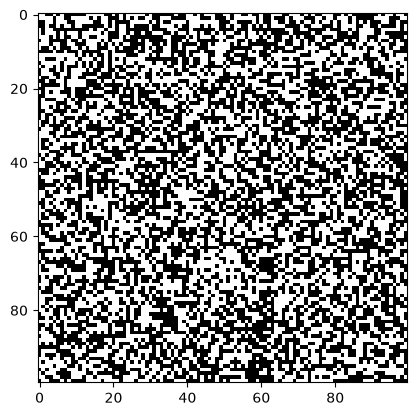

In [4]:
# check this repo if you want an optimized, complete code: https://github.com/MohamedElashri/IsingModel/tree/main

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

L = 100  # Lattice size (LxL grid)
T = 1.4  # Temperature remember T_C = 2 / np.log(1+np.sqrt(2)) for J=1, kB=1
J = 1  # Interaction strength
steps = 200  # Number of frames in the GIF

# Initialize lattice with random spins (-1 or +1)
lattice = np.random.choice([-1, 1], size=(L, L))

def monte_carlo_step(lattice, beta):
    """
    Perform one Monte Carlo step using the Metropolis algorithm.
    """
    for _ in range(L * L):  # Try flipping each spin once on average
        i, j = np.random.randint(0, L, size=2)  # Pick a random spin
        S = lattice[i, j]

        # Compute sum of nearest neighbors
        neighbors = (
            lattice[(i+1)%L, j] + lattice[i, (j+1)%L] +
            lattice[(i-1)%L, j] + lattice[i, (j-1)%L]
        )

        # Energy change if spin is flipped
        dE = 2 * J * S * neighbors

        # Metropolis criterion
        if dE < 0 or np.random.rand() < np.exp(-beta * dE):
            lattice[i, j] *= -1  # flip spin

# Set up Matplotlib figure
fig, ax = plt.subplots()
img = ax.imshow(lattice, cmap="gray", vmin=-1, vmax=1)

def update(frame):
    monte_carlo_step(lattice, beta=1/T)
    img.set_data(lattice)
    return img,

ani = animation.FuncAnimation(fig, update, frames=steps, interval=100, blit=False)

# ani.save(f"images/ising_model_T_{T}.gif", writer="pillow", fps=30)
plt.show()


## Simulations at different temperatures (1.4, 2.4, 5)

![](images/ising_model_T_1.4.gif)
![](images/ising_model_T_2.4.gif)
![](images/ising_model_T_5.gif)
